# 01 · Preprocessing — Li 2019 melanoma (malignant compartment)

Li et al. 2019 is an **immune-focused** melanoma atlas (MARS-seq): of 78,336 cells
only **1,160 are malignant**, the rest T/B/myeloid. We isolate the malignant
compartment, threshold thin samples by a **data-driven dominant multiplicative
gap**, integrate patients (Harmony), embed, and settle each sub-region's biology
*before* the Gate-1 call. Unlike a per-patient archipelago, Li's melanoma cells
form **one continuous sample-mixed axis** (two density poles of a single manifold,
not two lineages) — established below on the regenerated embedding + a
per-neighbourhood iLISI sweep, not on a scalar.

In [1]:
%matplotlib inline
import os, sys, glob, re, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset-run>
name = os.path.basename(os.getcwd())                    # e.g. Li2019_Skin-2 (output run dir)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Skin)
raw_name = re.sub(r'-\d+$', '', name)                   # strip run suffix -> raw folder Li2019_Skin
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Li2019_Skin-2 | category: Skin | raw: Li2019_Skin


### Load malignant compartment
The loader auto-detects MARS-seq **UMI counts** (`Exp_data_UMIcounts.mtx`),
CPM-normalises and log1p-transforms. We take the atlas `Malignant` calls and drop
any all-zero cells.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| expression: MARS-seq UMI counts -> CPM-normalised, log1p')
adata = adata[adata.obs.celltype == 'Malignant'].copy()
sc.pp.calculate_qc_metrics(adata, inplace=True, percent_top=None)
adata = adata[adata.obs.n_genes_by_counts >= 1].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Li2019_Skin
Done.
full atlas: (78336, 40979) | expression: MARS-seq UMI counts -> CPM-normalised, log1p
malignant: (1160, 40979) | samples: 20


### Sample thresholding — data-driven dominant multiplicative gap
Per-sample malignant counts drop off a cliff: **528, 400, 154, then 21, 12, ...**
The largest multiplicative gap in the sorted counts is **154 → 21 (7.3×)**, which
cleanly separates three substantial tumours from a ≤21-cell spillover tail. Unlike
Tirosh 2016 — whose top gap sat in a noisy singleton tail and needed a
median-floor restriction — Li's *dominant* gap is itself the correct cut, so no
restriction is applied. We cut at the geometric mean of that gap.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))                       # dominant multiplicative gap
thresh = int(np.sqrt(vals[gap] * vals[gap+1]))     # geometric-mean cut
print('sorted per-sample malignant counts:', n.values.tolist())
print(f'dominant gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples {list(keep)} -> {adata.shape[0]} cells')

sorted per-sample malignant counts: [528, 400, 154, 21, 12, 10, 9, 4, 4, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1]
dominant gap: 154 -> 21 (ratio 7.33)
derived threshold (geometric mean) = 56
kept 3/20 samples ['p25', 'p21', 'p26'] -> 1082 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta=10` (strong patient correction — melanoma malignant programs are strongly
patient-private; θ≤5 leaves under-mixed per-patient fragments, θ=10 interleaves all
three patients on one axis and iLISI plateaus) and `n_pcs=30` (mid of the robust
20–40 range; the elongated 1-D topology is invariant across it). **No `sc.pp.scale`**
before PCA — it is absent from the reference protocol.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)                       # no scaling
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 217 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 217


### Cell-cycle phase (scored — no phase column in this atlas)
Li 2019's obs carries no `cell_cycle_phase`, so we score S/G2M with the standard
Tirosh/Regev gene sets to check that cell cycle does not confound the embryonic
signatures (a Kürten-lobe failure mode).

In [6]:
s_genes = ['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes = ['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cell_cycle_phase'] = adata.obs['phase']
print('cell-cycle phases:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phases: {'G1': 574, 'S': 271, 'G2M': 237}


### Gate 1 — mixing & continuity (on the embedding, not a scalar)
Three reads, all off the regenerated manifold: (i) the **kNN graph** scanpy/scFates
actually use is one connected component at every θ×n_pcs; (ii) **each patient spans
both density lobes** of the manifold (a patient-shared axis, not an archipelago);
(iii) **per-neighbourhood iLISI** rises with integration strength and plateaus. The
two visual density lobes are poles of one continuous axis — confirmed
biologically-identical below.

In [7]:
def ilisi(emb, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(emb).kneighbors(emb, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes
    return np.array([1.0/np.sum(pd.Series(lab[nn[i]]).value_counts(normalize=True).values**2)
                     for i in range(emb.shape[0])])
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print('=== theta x n_pcs sweep (iLISI median / kNN-graph components) ===')
for theta in [2,5,10,20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
    rep = adata.obsm['X_pca_harmony']
    for npcs in [20,30,40]:
        sc.pp.neighbors(adata, n_pcs=npcs, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
        ncomp, _ = connected_components(adata.obsp['connectivities'], directed=False)
        il = np.median(ilisi(rep[:,:npcs], samp))
        if npcs == 30:
            print(f'  theta={theta:2d} npcs={npcs}: iLISI_med={il:.2f}/{nsamp}  kNN-graph components={ncomp}')
# settle at theta=10, n_pcs=30
sce.pp.harmony_integrate(adata, 'sample', theta=10, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', n_neighbors=15, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
ncomp,_ = connected_components(adata.obsp['connectivities'], directed=False)
il10 = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:30], samp))
from sklearn.cluster import KMeans
lobe = KMeans(2, random_state=0, n_init=10).fit_predict(adata.obsm['X_umap'])
print(f'\nfinal theta=10 n_pcs=30: kNN-graph components={ncomp}; iLISI_med={il10:.2f}/{nsamp}')
print('each patient spans BOTH density lobes (fraction in lobe-1):')
for s in keep:
    m = adata.obs['sample'].values == s
    print(f'  {s}: {lobe[m].mean()*100:4.0f}% lobe-1  ({(~(lobe[m].astype(bool))).mean()*100:.0f}% lobe-0)')
assert ncomp == 1 and il10 > 1.2 and all(0.15 < lobe[adata.obs['sample'].values==s].mean() < 0.85 for s in keep), \
    'Gate 1 FAILED: not one continuous sample-mixed manifold'
print('Gate 1: one kNN component + every patient traverses the axis + iLISI plateau -> GO')

=== theta x n_pcs sweep (iLISI median / kNN-graph components) ===
  theta= 2 npcs=30: iLISI_med=1.30/3  kNN-graph components=1
  theta= 5 npcs=30: iLISI_med=1.72/3  kNN-graph components=1
  theta=10 npcs=30: iLISI_med=1.76/3  kNN-graph components=1
  theta=20 npcs=30: iLISI_med=1.80/3  kNN-graph components=1

final theta=10 n_pcs=30: kNN-graph components=1; iLISI_med=1.76/3
each patient spans BOTH density lobes (fraction in lobe-1):
  p25:   41% lobe-1  (59% lobe-0)
  p21:   57% lobe-1  (43% lobe-0)
  p26:   42% lobe-1  (58% lobe-0)
Gate 1: one kNN component + every patient traverses the axis + iLISI plateau -> GO


### Subtype annotation (data markers + published identity)
Li 2019 is immune-focused and reports **no malignant transcriptional subtypes**, so
annotation follows the standing rule using **both** (a) the published identity —
these are melanoma (neural-crest-lineage) malignant cells — and (b) data-derived
marker programs. Low-resolution Leiden clusters are labelled by their dominant
program (melanocytic / AP1-stress / cycling). The clusters are transcriptionally
near-identical (one compartment); the labels annotate position along the single
axis, not separate lineages.

In [8]:
sc.tl.leiden(adata, resolution=0.3, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
def _sig(genes):
    gg = [g for g in genes if g in adata.var_names]
    return np.asarray(adata[:, gg].X.mean(1)).ravel() if gg else np.zeros(adata.n_obs)
prog = {'Melanocytic':['MITF','MLANA','PMEL','TYR','DCT','TYRP1'],
        'AP1':['FOS','JUN','JUNB','FOSB'],
        'CellCycle':['MKI67','TOP2A','CENPF','CCNB1']}
for k,gs in prog.items(): adata.obs['p_'+k] = _sig(gs)
prof = adata.obs.groupby('leiden', observed=True)[['p_'+k for k in prog]].mean().round(3)
print('marker-program means per Leiden cluster:'); print(prof.to_string())
cc = adata.obs.groupby('leiden', observed=True)['p_CellCycle'].mean()
ap = adata.obs.groupby('leiden', observed=True)['p_AP1'].mean()
cyc_cl = cc.idxmax(); stress_cl = ap.drop(cyc_cl).idxmax()
sub_map = {}
for cl in adata.obs.leiden.cat.categories:
    sub_map[cl] = 'Cycling' if cl==cyc_cl else ('Stress-AP1' if cl==stress_cl else 'Melanocytic')
adata.obs['subtype'] = adata.obs['leiden'].map(sub_map).astype('category')
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())
print('cell cycle vs signatures checked in 03; clusters are one melanocytic compartment along the axis')

marker-program means per Leiden cluster:
        p_Melanocytic  p_AP1  p_CellCycle
leiden                                   
0               0.274  0.061        0.013
1               0.411  0.024        0.024
2               0.164  0.047        0.022
subtypes: {'Stress-AP1': 540, 'Cycling': 510, 'Melanocytic': 32}
cell cycle vs signatures checked in 03; clusters are one melanocytic compartment along the axis


### Save processed data

In [9]:
for c in adata.obs.columns:
    if adata.obs[c].dtype == object:
        adata.obs[c] = adata.obs[c].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1082, 18161)


### Sample-integration figure (deliverable `samples.pdf`)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, colour = sample.
Cross-sample intermixing across the strip is the Gate-1 batch-integration evidence;
orientation (pseudotime sign) is fixed in 02, so a plain x-flip is used here.

saved samples.pdf | malignant cells: 1082


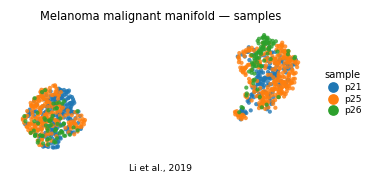

In [10]:
traj = adata.copy()
xy = traj.obsm['X_umap'].astype(float)
traj.obsm['X_umap'] = np.column_stack([-xy[:,0], xy[:,1]])
xl = traj.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(traj, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.3, fontsize=6, title='sample', title_fontsize=6.5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Melanoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Li et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | malignant cells:', traj.shape[0])